## Задача 1. Поворот и отражение правильного шестиугольника
Условие. Постройте правильный шестиугольник с центром в начале координат и
радиусом 1. Вершины шестиугольника задаются формулами:
x[k] = cos(2πk/6), y[k] = sin(2πk/6), k = 0, 1, …, 5
Замкните контур (добавьте первую вершину в конец). Затем:
1. Поверните шестиугольник на 45° против часовой стрелки матрицей поворота 2×2.
2. Отразите исходный шестиугольник относительно прямой y = x. Матрица
отражения относительно этой прямой:
( 0 1 ; 1 0 )
3. Постройте исходный, повёрнутый и отражённый шестиугольники на одном
графике (три цвета, легенда, set_aspect('equal') ).
Что сдать: скрипт, график, и ответ на вопрос: почему отражённый шестиугольник
выглядит «повёрнутым», хотя это отражение, а не поворот? (Подсказка: сравните
матрицы поворота на 90° и отражения относительно y = x — они совпадают с
точностью до знака.)



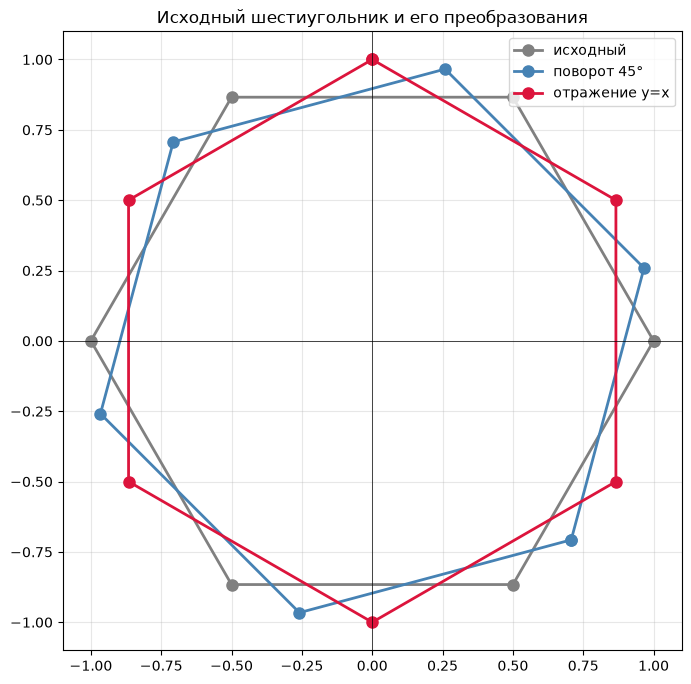

In [7]:
import numpy as np
import matplotlib.pyplot as plt

six = np.array(
    [[np.cos(2*np.pi*k/6), np.sin(2*np.pi*k/6)] for k in range(6)]
)
six = np.vstack([six, six[0]])

theta = np.deg2rad(45) # поворот на 45 градусов
rotate = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta), np.cos(theta)],
])

six_rotated = six @ rotate

reflect = np.array([
    [0.0, 1.0],
    [1.0, 0.0],
])

six_reflected = six @ reflect

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(six[:, 0], six[:, 1], 'o-', color='gray', label='исходный', lw=2, markersize=8)
ax.plot(six_rotated[:, 0], six_rotated[:, 1], 'o-', color='steelblue', label='поворот 45°', lw=2, markersize=8)
ax.plot(six_reflected[:, 0], six_reflected[:, 1], 'o-', color='crimson', label='отражение y=x', lw=2, markersize=8)
ax.axhline(0, color='black', lw=0.5)
ax.axvline(0, color='black', lw=0.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title('Исходный шестиугольник и его преобразования')
plt.tight_layout()
plt.show()





## Задача 2. Композиция преобразований и обратное преобразование
Условие. Дан набор из 200 случайных точек, равномерно распределённых в квадрате
[−2, 2] × [−2, 2] (используйте np.random.default_rng(42) ). Выполните над точками
композицию:
1. Масштабирование: s = 1.5, s = 0.5.
2. Поворот на 60° против часовой стрелки.
3. Перенос на вектор (1, −1) — через однородные координаты 3×3.
Постройте исходное и преобразованное облака на одном графике. Затем восстановите
исходные точки, применив обратные преобразования в обратном порядке:
1. Обратный перенос: (−1, 1).
2. Обратный поворот: на −60°.
3. Обратный масштаб: s = 1/1.5, s = 1/0.5.
Проверьте через np.allclose , что восстановленные точки совпадают с исходными с
точностью 1e−12.
Что сдать: скрипт, график «исходные / преобразованные / восстановленные», и ответ
на вопрос: почему обратные преобразования нужно применять в обратном порядке?
−1 −1 −1
Что произойдёт, если применить их в прямом порядке? (Подсказка: (AB) = B A .)


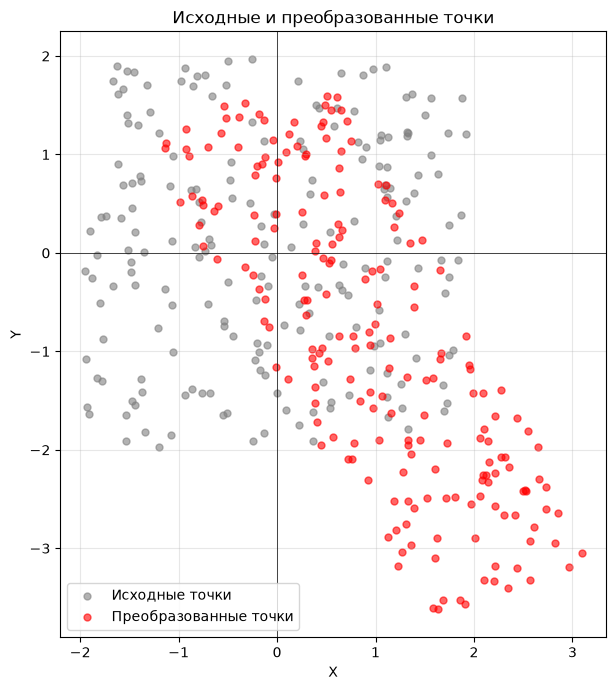

True


In [10]:
rng = np.random.default_rng(42)
p = rng.uniform(low=-2.0, high=2.0, size=(200, 2))

sx, sy = 1.5, 0.5
scale = np.array([
    [sx, 0.0],
    [0.0, sy],
])

p_scale = p @ scale

theta = np.deg2rad(60) # поворот на 45 градусов
rotate = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta), np.cos(theta)],
])

p_rotate = p_scale @ rotate

tx, ty = 1.0, -1.0
translate = np.array([
    [1.0, 0.0, tx],
    [0.0, 1.0, ty],
    [0.0, 0.0, 1.0],
])

# 1. Добавляем столбец из единиц: (200, 2) -> (200, 3)
p_h = np.hstack([p_rotate, np.ones((p_rotate.shape[0], 1))])

# 2. Умножаем на транспонированную матрицу переноса (так как точки в строках)
p_th = p_h @ translate.T

# 3. Отбрасываем третий столбец обратно: (200, 3) -> (200, 2)
p_translated = p_th[:, :2]

fig, ax = plt.subplots(figsize=(7, 7))

# Исходные точки
ax.scatter(
    p[:, 0], p[:, 1],
    color='gray',
    label='Исходные точки',
    s=25,
    alpha=0.6
)

# Преобразованные точки
ax.scatter(
    p_translated[:, 0], p_translated[:, 1],
    color='red',
    label='Преобразованные точки',
    s=25,
    alpha=0.6
)

# Координатные оси
ax.axhline(0, color='black', lw=0.5)
ax.axvline(0, color='black', lw=0.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Исходные и преобразованные точки')

plt.tight_layout()
plt.show()

# 1. Обратный перенос через однородные координаты
translate_inv = np.array([
    [1.0, 0.0, -tx],
    [0.0, 1.0, -ty],
    [0.0, 0.0, 1.0],
])

p_h = np.hstack([
    p_translated,
    np.ones((p_translated.shape[0], 1))
])

p_th = p_h @ translate_inv.T
p_untranslated = p_th[:, :2]

# 2. Обратный поворот на -60 градусов
rotate_inv = np.array([
    [np.cos(-theta), -np.sin(-theta)],
    [np.sin(-theta), np.cos(-theta)],
])

p_unrotated = p_untranslated @ rotate_inv

# 3. Обратное масштабирование
scale_inv = np.array([
    [1 / sx, 0.0],
    [0.0, 1 / sy],
])

p_restored = p_unrotated @ scale_inv

print(np.allclose(p, p_restored, rtol=0, atol=1e-12))
